# Health records and EEG reports: TUAB, the TUH training cohort and HEEDB

📄 **[PDF version](clinical_records_analytics.pdf)**

What the three corpora we train on say about their patients, beyond the EEG: **age and sex**, the
**normal / abnormal** verdict of the EEG report, the patients' **pathologies** (seizure disorders, stroke,
dementia, psychiatric diagnoses, headache and migraine, sleep disorders, tumours and others) and the **types of
abnormality** the reports name (slowing, epileptiform discharges, seizures, suppression, ...). Every statistic is
computed on one harmonised per-recording table (`labram/eval/clinical_analytics.py`), so the corpora read side
by side.

* **TUAB** (v3.0.1, 2,993 recordings): the normal / abnormal benchmark; its test split is our TUAB eval set.
* **TUH cohort** (`all_both_v3_anymiss`, 31,312 recordings): the TUH part of E2 / E2L / E2P.
* **HEEDB** (`heedb_routine_v1`, 71,805 adult routine recordings): the Harvard part of the same runs.

HEEDB is under a data use agreement: every HEEDB cell computed from fewer than 10 recordings is blank, and no
row-level data is shown.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from labram.eval import clinical_analytics as ca
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

pd.set_option("display.max_columns", 40)
df = ca.load_all()
CORPORA = ["TUAB", "TUH cohort", "HEEDB"]
COLORS = {"TUAB": "#7a7a7a", "TUH cohort": "#e07b39", "HEEDB": "#3a6ea5"}
df["age_group"] = ca.age_group(df["age"])
PX = ca.pathology_names(df)
AB = ca.abnormal_type_names(df)


def finish(fig, axes=None):
    fig.tight_layout()
    if axes is not None and len(axes) > 1:
        panel_labels(list(axes))
    assert_max_columns(fig)
    plt.show()


def heat(ax, table, title, fmt="{:.0f}", cmap="viridis", vmax=None):
    data = table.to_numpy(dtype=float)
    im = ax.imshow(np.ma.masked_invalid(data), aspect="auto", cmap=cmap, vmin=0, vmax=vmax)
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(table.shape[0]), table.index, fontsize=8)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            if np.isfinite(data[i, j]):
                ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=7,
                        color="white" if data[i, j] < (vmax or np.nanmax(data)) * 0.6 else "black")
    ax.set_title(title)
    return im

## 1. Sources and definitions

### Table 1.1. Where each kind of information comes from

| | TUAB / TUH cohort | HEEDB |
|---|---|---|
| Age, sex | EDF header (age), cohort metadata | BDSP metadata (`AgeAtVisit`, sex) |
| Normal / abnormal | TUAB folder label; else the NEDC report finding (TUH cohort) | the EEG report (BDSP findings), unlabelled when the session has no report |
| Pathologies | NEDC TUEG clinical sheet: 15 Y/N diagnosis columns per session, plus keyword mentions in its free-text "Other diagnosis" | per-patient ICD-10 codes (neurology extract): TUH-aligned `dx_*` flags and ICD-10 groups `icd_*` |
| Abnormality types | the sheet's "abnormal due to" text, mapped to reason categories (`meta_analysis.REPORT_REASONS`) | report finding groups (`fg_*`) |
| Missing information | session not in the sheet → unknown | patient without any ICD-10 record → unknown |

Three caveats shape every comparison below:

* **HEEDB pathologies are per patient and undated.** An ICD-10 code may predate or postdate the EEG; the TUH
  sheet describes the session. HEEDB rates are therefore "ever diagnosed", TUH rates "noted at this EEG".
* **TUH free-text categories are mentions.** Headache / migraine, sleep disorder, tumour, syncope and the other
  keyword categories (Table 1.2, marked *mention*) count a session when its "Other diagnosis" text names the
  condition; a session that does not name it is counted as not mentioned, which is not evidence of absence.
  These rates are **lower bounds**.
* **The NEDC sheet leaves its diagnosis columns almost empty for TUAB sessions** (seizure 0.1 %, epilepsy 0.04 %
  against 8.4 % / 3.4 % for the other TUEG sessions of the cohort), although 50 % of them have "Other diagnosis"
  text and 35 % an "abnormal due to" reason. TUAB's near-zero diagnosis rates mean *not annotated*, not healthy.

A corpus that does not code a category at all (e.g. HEEDB's neurology extract has no psychiatric or injury
codes besides depression and ADHD) is left blank, never 0.

### Table 1.2. Pathology categories and their source columns

`tuh` / `heedb` list the columns OR-ed into the category (`kw_*` = keyword mention in the TUH free text,
`dx_*` / `icd_*` = coded diagnosis); `–` = not coded in that corpus.

In [2]:
rows = []
for name, (tuh, heedb) in ca.PATHOLOGIES.items():
    rows.append({"category": name, "tuh": ", ".join(tuh) or "–", "heedb": ", ".join(heedb) or "–",
                 "TUH kind": "mention (lower bound)" if name in ca.KEYWORD_PATHOLOGIES else "Y/N column"})
display(numbered_table(pd.DataFrame(rows).set_index("category"), "1.2", "Pathology categories"))

,tuh,heedb,TUH kind
category,,,
seizure_epilepsy,"dx_clinical_seizure, dx_epilepsy, dx_electrographic_seizure","dx_clinical_seizure, dx_epilepsy",Y/N column
stroke_cerebrovascular,dx_stroke,"dx_stroke, icd_cerebrovascular_diseases",Y/N column
dementia,"dx_dementia, dx_alzheimers","dx_dementia, dx_alzheimers",Y/N column
parkinson_movement,dx_parkinsons,"dx_parkinsons, icd_movement_and_cerebellar_disorders",Y/N column
multiple_sclerosis,dx_ms,dx_ms,Y/N column
tbi,dx_tbi,–,Y/N column
depression,dx_depression,dx_depression,Y/N column
anxiety,dx_anxiety,–,Y/N column
bipolar,dx_bipolar,–,Y/N column


### Table 1.3. Recordings with the pathology known, and positives

Per corpus and category: `known` = recordings whose status for the category is known (TUH: the session is in the
sheet; HEEDB: the patient has an ICD-10 record), `positive` = those with the category. HEEDB counts under 10
are blank.

In [3]:
kc = ca.known_counts(df)
t = kc.pivot(index="pathology", columns="corpus", values=["known", "positive"]).reindex(PX)
t = t.reindex(columns=pd.MultiIndex.from_product([["known", "positive"], CORPORA]))
pos = t["positive"]["HEEDB"]
t[("positive", "HEEDB")] = pos.where((pos >= ca.SMALL_CELL) | (pos == 0))
display(numbered_table(t, "1.3", "Known and positive recordings per category", precision=0))

## 2. Who the recordings come from: age, sex and the EEG verdict

### Table 2.1. Corpus overview

Recordings, distinct patients, age (mean, SD, years), the share of women, the EEG report's verdict
(normal / abnormal / unknown, % of recordings) and the share with health-record information (Table 1.1).

In [4]:
display(numbered_table(ca.overview(df).reindex(CORPORA), "2.1", "Corpus overview", precision=1))

,recordings,patients,age mean,age SD,female %,normal %,abnormal %,status unknown %,health record %
corpus,,,,,,,,,
TUAB,2993,2329,49.1,17.4,53.3,50.8,49.2,0.0,85.5
TUH cohort,31312,13978,52.3,17.5,51.1,39.2,53.0,7.9,91.2
HEEDB,71805,57678,54.0,19.8,51.5,20.1,30.6,49.2,90.6


### Figure 2.1. Age distribution by EEG verdict

Share of recordings per 5-year age bin (each curve sums to 100 %), for normal (solid) and abnormal (dashed)
reports; adults 18+. (a) TUAB and the TUH cohort; (b) HEEDB.

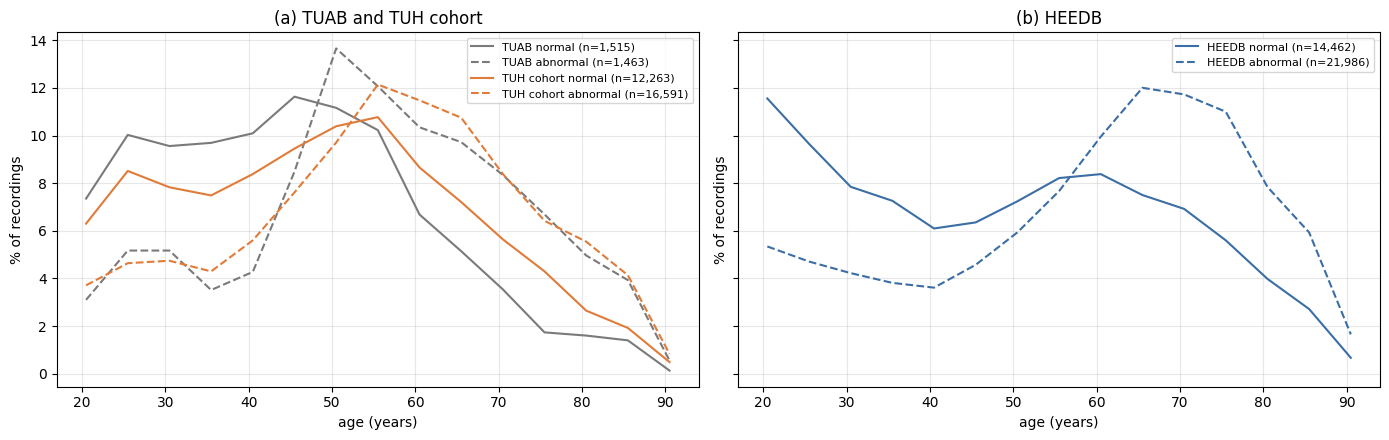

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
bins = np.arange(18, 96, 5)
for ax, corpora in zip(axes, (["TUAB", "TUH cohort"], ["HEEDB"])):
    for c in corpora:
        for status, ls in (("normal", "-"), ("abnormal", "--")):
            a = df[(df.corpus == c) & (df.status == status)]["age"].dropna()
            h, _ = np.histogram(a, bins=bins)
            ax.plot(bins[:-1] + 2.5, 100 * h / max(h.sum(), 1), ls, color=COLORS[c], label=f"{c} {status} (n={len(a):,})")
    ax.set_xlabel("age (years)"); ax.set_ylabel("% of recordings"); ax.legend(fontsize=8); ax.grid(alpha=.3)
axes[0].set_title("TUAB and TUH cohort"); axes[1].set_title("HEEDB")
finish(fig, axes)

### Table 2.2. TUAB: recordings by age group, sex and EEG verdict

Counts per age group (rows) and sex × verdict (columns); recordings with unknown sex are left out.

In [6]:
t = ca.age_sex_status(df, "TUAB")

display(numbered_table(t, "2.2", "TUAB: age x sex x verdict", precision=0))

### Table 2.3. TUH cohort: recordings by age group, sex and EEG verdict

Counts per age group (rows) and sex × verdict (columns); recordings with unknown sex are left out.

In [7]:
t = ca.age_sex_status(df, "TUH cohort")

display(numbered_table(t, "2.3", "TUH cohort: age x sex x verdict", precision=0))

### Table 2.4. HEEDB: recordings by age group, sex and EEG verdict

Counts per age group (rows) and sex × verdict (columns); recordings with unknown sex are left out.
Cells under 10 recordings are blank (DUA).

In [8]:
t = ca.age_sex_status(df, "HEEDB")
t = t.where(t >= ca.SMALL_CELL)
display(numbered_table(t, "2.4", "HEEDB: age x sex x verdict", precision=0))

### Figure 2.2. Share of abnormal EEGs by age group and sex

Abnormal % among recordings with a known verdict, Eq. (2.1), per age group; women solid, men dashed.
(a) TUAB and the TUH cohort; (b) HEEDB. A point needs at least 10 recordings.

$$
a_{g} = 100\,\frac{\#\{i \in g : \text{report}_i = \text{abnormal}\}}{\#\{i \in g : \text{report}_i \in \{\text{normal}, \text{abnormal}\}\}}
\tag{2.1}
$$

where $g$ is a set of recordings (an age group of one sex and corpus).

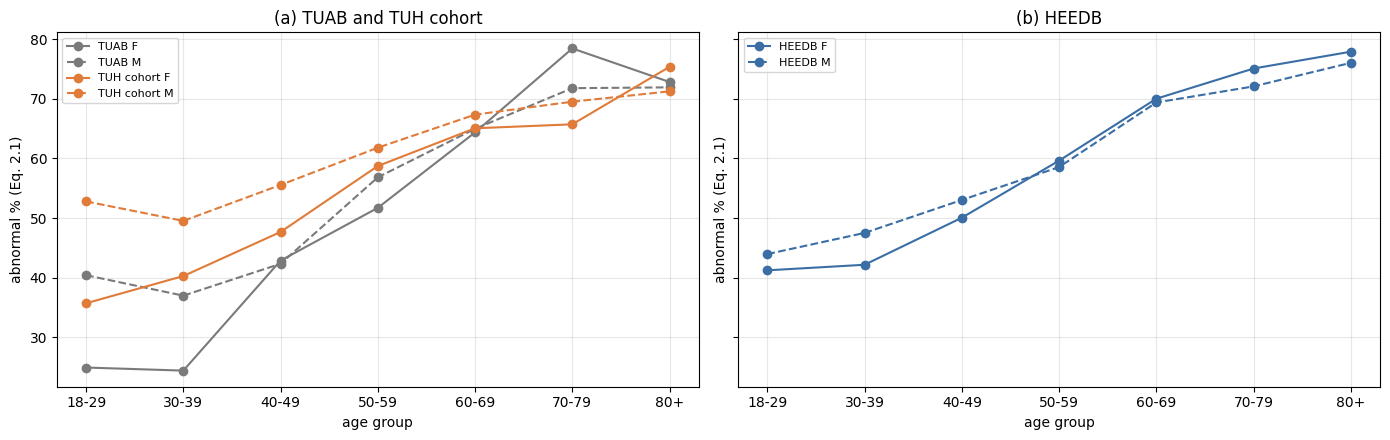

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, corpora in zip(axes, (["TUAB", "TUH cohort"], ["HEEDB"])):
    for c in corpora:
        for sex, ls in (("F", "-"), ("M", "--")):
            g = df[(df.corpus == c) & (df.sex == sex) & df.status.isin(["normal", "abnormal"])]
            r = g.groupby("age_group", observed=True)["status"].agg(lambda s: 100 * s.eq("abnormal").mean() if len(s) >= ca.SMALL_CELL else np.nan)
            ax.plot(r.index.astype(str), r.values, ls, marker="o", color=COLORS[c], label=f"{c} {sex}")
    ax.set_xlabel("age group"); ax.set_ylabel("abnormal % (Eq. 2.1)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
axes[0].set_title("TUAB and TUH cohort"); axes[1].set_title("HEEDB")
finish(fig, axes)

## 3. Pathologies

For a corpus and category $p$, the prevalence counts only the recordings whose status for $p$ is known
(Table 1.3):

$$
\pi_{p} = 100\,\frac{\#\{i : x_{ip} = 1\}}{\#\{i : x_{ip} \in \{0, 1\}\}}
\tag{3.1}
$$

where $x_{ip} = 1$ when recording $i$ has category $p$, $0$ when it is known not to (or, for a mention category,
not mentioned), and unknown otherwise (`clinical_analytics.prevalence`).

### Table 3.1. Prevalence per corpus (%)

Eq. (3.1) per category and corpus; *mention* categories (Table 1.2) are lower bounds for TUH; blank = not coded
(or a HEEDB count under 10).

In [10]:
prev = ca.prevalence(df).T[CORPORA]
display(numbered_table(prev, "3.1", "Prevalence per corpus (%)", precision=1))

,TUAB,TUH cohort,HEEDB
seizure_epilepsy,0.2,9.0,35.4
stroke_cerebrovascular,0.2,3.9,14.6
dementia,0.0,0.3,7.7
parkinson_movement,0.0,0.0,14.6
multiple_sclerosis,0.4,0.2,1.4
tbi,0.1,1.3,–
depression,0.1,0.5,20.0
anxiety,0.0,0.4,–
bipolar,1.6,1.1,–
schizophrenia,0.0,0.3,–


### Figure 3.1. Prevalence by age group

Eq. (3.1) per category (rows) and age group (columns), %. (a) TUH cohort; (b) HEEDB. Categories not coded in
the corpus are left out; HEEDB cells under 10 positives are blank.

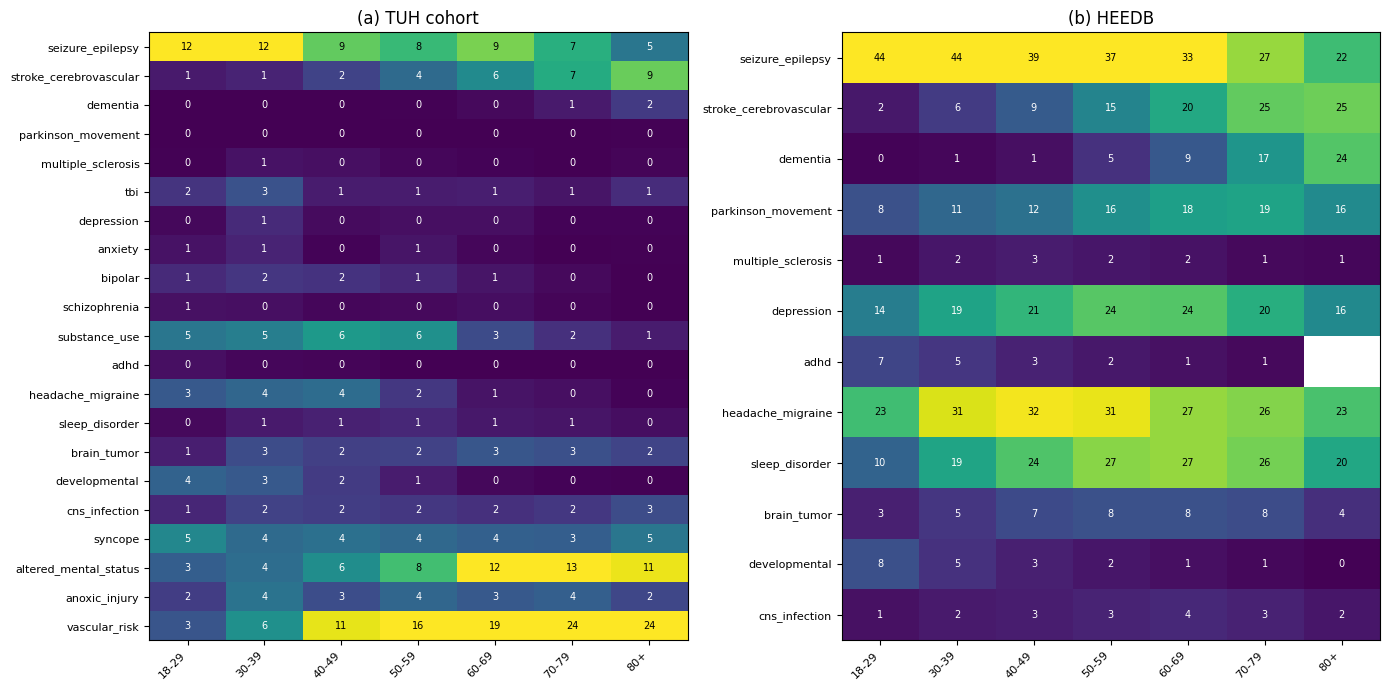

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, c in zip(axes, ["TUH cohort", "HEEDB"]):
    p = ca.prevalence(df[df.corpus == c], by="age_group").droplevel(0)
    p = p.loc[:, p.notna().any()].T
    heat(ax, p, c, fmt="{:.0f}", vmax=np.nanpercentile(p.to_numpy(dtype=float), 95))
finish(fig, axes)

### Table 3.2. Prevalence by sex (%)

Eq. (3.1) per corpus and sex.

In [12]:
s = ca.prevalence(df[df.sex.isin(["F", "M"])], by="sex")
s = s.T.reindex(columns=pd.MultiIndex.from_product([CORPORA, ["F", "M"]]))
s.columns = [f"{a} {b}" for a, b in s.columns]
display(numbered_table(s, "3.2", "Prevalence by sex (%)", precision=1))

,TUAB F,TUAB M,TUH cohort F,TUH cohort M,HEEDB F,HEEDB M
seizure_epilepsy,0.2,0.1,8.7,9.3,35.8,35.1
stroke_cerebrovascular,0.3,0.2,3.7,4.2,13.7,15.5
dementia,0.0,0.1,0.3,0.3,7.3,8.1
parkinson_movement,0.0,0.0,0.0,0.0,14.0,15.2
multiple_sclerosis,0.4,0.3,0.4,0.1,1.9,0.9
tbi,0.0,0.2,0.7,1.9,–,–
depression,0.1,0.1,0.6,0.3,22.6,17.3
anxiety,0.0,0.0,0.5,0.4,–,–
bipolar,2.1,1.2,1.4,0.9,–,–
schizophrenia,0.0,0.0,0.1,0.5,–,–


### Table 3.3. How often the EEG is abnormal with and without each pathology

Among recordings with a known verdict, the abnormal share, Eq. (2.1), of those with the category (`with`) and
of those known not to have it (`without`); categories with at least 10 recordings.

$$
\Delta a_p = a_{\{i:\,x_{ip}=1\}} - a_{\{i:\,x_{ip}=0\}}
\tag{3.2}
$$

is the difference in percentage points (`clinical_analytics.abnormal_rate_by_pathology`).

In [13]:
ar = ca.abnormal_rate_by_pathology(df)
ar["Δ (pp)"] = ar["abnormal % with"] - ar["abnormal % without"]
t = ar.pivot(index="pathology", columns="corpus", values="Δ (pp)").reindex(columns=CORPORA)
t2 = ar.pivot(index="pathology", columns="corpus", values="abnormal % with").reindex(columns=CORPORA)
out = pd.concat({"abnormal % with": t2, "Δ (pp), Eq. 3.2": t}, axis=1).reindex(PX).dropna(how="all")
display(numbered_table(out, "3.3", "Abnormal EEG share with / without each pathology", precision=1))

### Figure 3.2. Abnormal-EEG excess by pathology

$\Delta a_p$ (Eq. (3.2), percentage points) per category: (a) TUH cohort; (b) HEEDB. Positive = the EEG is more
often abnormal in patients with the category than in those without it.

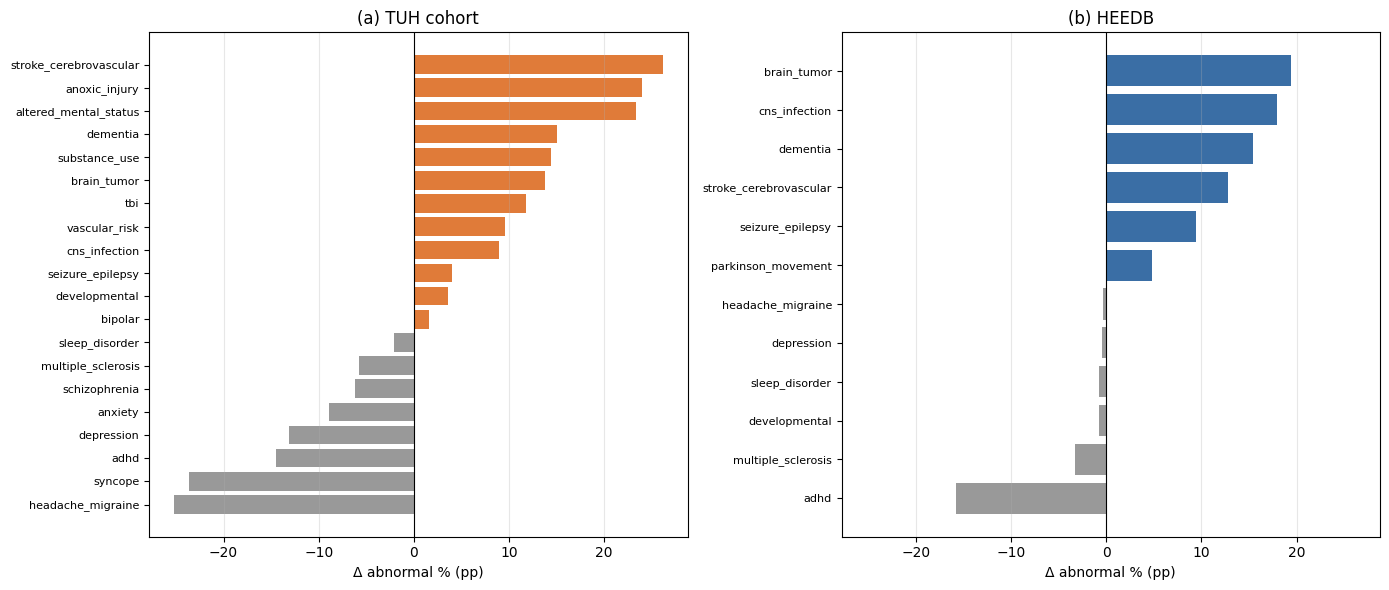

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, c in zip(axes, ["TUH cohort", "HEEDB"]):
    d = ar[ar.corpus == c].set_index("pathology")["Δ (pp)"].sort_values()
    ax.barh(d.index, d.values, color=[COLORS[c] if v >= 0 else "#999" for v in d.values])
    ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Δ abnormal % (pp)"); ax.set_title(c); ax.grid(alpha=.3, axis="x")
    ax.tick_params(axis="y", labelsize=8)
finish(fig, axes)

### Figure 3.3. Headache / migraine: prevalence by age and sex

Eq. (3.1) for the headache / migraine category per age group, women solid, men dashed: (a) TUAB and the TUH
cohort (mentions in the "Other diagnosis" text, lower bounds); (b) HEEDB (ICD-10 headache disorders, G43/G44).

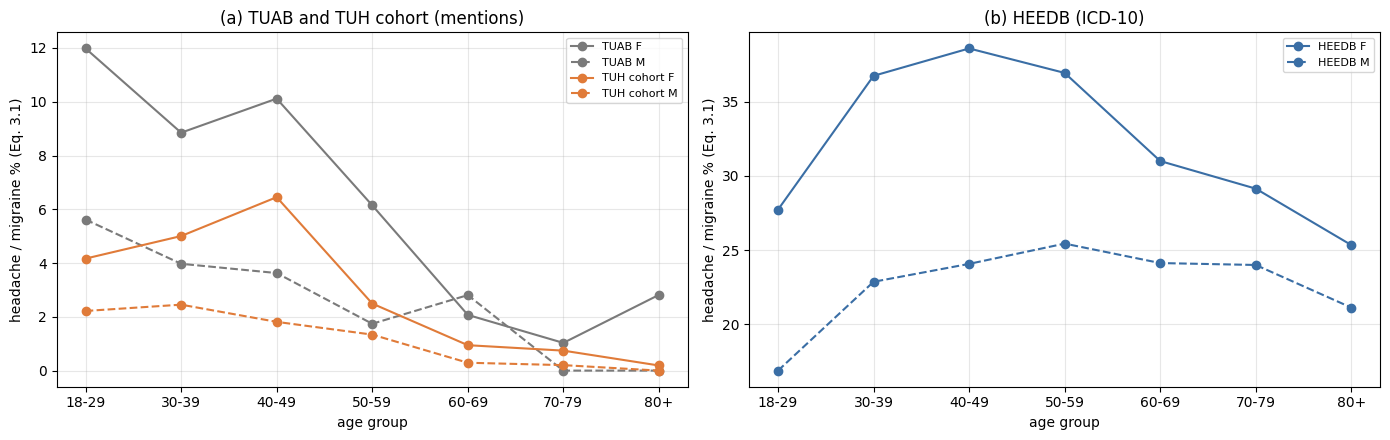

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, corpora in zip(axes, (["TUAB", "TUH cohort"], ["HEEDB"])):
    for c in corpora:
        for sex, ls in (("F", "-"), ("M", "--")):
            g = df[(df.corpus == c) & (df.sex == sex)]
            p = ca.prevalence(g, by="age_group")["headache_migraine"].droplevel(0)
            ax.plot(p.index.astype(str), p.values, ls, marker="o", color=COLORS[c], label=f"{c} {sex}")
    ax.set_xlabel("age group"); ax.set_ylabel("headache / migraine % (Eq. 3.1)"); ax.legend(fontsize=8); ax.grid(alpha=.3)
axes[0].set_title("TUAB and TUH cohort (mentions)"); axes[1].set_title("HEEDB (ICD-10)")
finish(fig, axes)

### Table 3.4. HEEDB: co-occurrence of pathologies

For each row category, the share (%) of its patients' recordings that also carry the column category:

$$
c_{pq} = 100\,\frac{\#\{i : x_{ip} = 1,\ x_{iq} = 1\}}{\#\{i : x_{ip} = 1,\ x_{iq} \in \{0,1\}\}}
\tag{3.3}
$$

(`clinical_analytics.co_occurrence`); the diagonal is 100. Cells under 10 recordings are blank.

In [16]:
names = [p for p in PX if df.loc[df.corpus == "HEEDB", f"px_{p}"].notna().any()]
co = ca.co_occurrence(df, "HEEDB", names)
display(numbered_table(co, "3.4", "HEEDB co-occurrence (%)", precision=0))

,seizure_epilepsy,stroke_cerebrovascular,dementia,parkinson_movement,multiple_sclerosis,depression,adhd,headache_migraine,sleep_disorder,brain_tumor,developmental,cns_infection
seizure_epilepsy,100,19,9,21,2,29,4,41,30,11,6,4
stroke_cerebrovascular,46,100,17,29,2,34,2,53,38,9,2,5
dementia,43,33,100,32,2,40,2,39,39,7,2,5
parkinson_movement,50,29,17,100,4,42,5,49,46,9,5,6
multiple_sclerosis,42,16,9,38,100,36,4,43,35,4,1,10
depression,50,25,15,31,3,100,7,52,49,9,4,5
adhd,56,11,6,25,2,51,100,48,44,7,12,4
headache_migraine,52,28,11,26,2,38,5,100,39,12,3,5
sleep_disorder,47,25,14,31,2,44,6,49,100,9,4,5
brain_tumor,62,21,8,21,1,28,3,54,30,100,2,7


### Table 3.5. TUH cohort: co-occurrence of pathologies

Eq. (3.3) for the TUH cohort, categories with at least 50 positives.

In [17]:
kc_t = kc[(kc.corpus == "TUH cohort") & (kc.positive >= 50)].pathology.tolist()
display(numbered_table(ca.co_occurrence(df, "TUH cohort", kc_t), "3.5", "TUH cohort co-occurrence (%)", precision=0))

,seizure_epilepsy,stroke_cerebrovascular,dementia,multiple_sclerosis,tbi,depression,anxiety,bipolar,schizophrenia,substance_use,headache_migraine,sleep_disorder,brain_tumor,developmental,cns_infection,syncope,altered_mental_status,anoxic_injury,vascular_risk
seizure_epilepsy,100,13,1,0,5,1,2,1,2,7,2,1,5,1,2,2,6,2,8
stroke_cerebrovascular,29,100,3,0,6,1,1,2,2,5,0,1,1,0,0,2,12,1,17
dementia,33,36,100,0,1,2,2,0,5,2,0,4,4,0,1,2,25,0,20
multiple_sclerosis,0,0,0,100,5,0,0,5,0,6,23,0,0,0,0,18,15,0,9
tbi,37,18,0,1,100,1,1,0,0,7,2,0,1,3,1,1,8,3,6
depression,26,5,2,0,3,100,37,5,3,24,2,2,1,0,1,3,1,2,29
anxiety,44,12,2,0,3,39,100,8,4,34,14,2,0,0,1,2,1,0,11
bipolar,9,6,0,1,0,2,3,100,4,10,3,1,0,2,1,6,4,3,19
schizophrenia,57,23,4,0,0,4,5,13,100,8,0,4,0,1,0,0,18,0,24
substance_use,15,5,0,0,2,3,3,3,1,100,1,0,0,1,1,3,7,4,16


## 4. What makes an EEG abnormal: abnormality types

Among abnormal recordings whose report gives a reason (TUH: an "abnormal due to" text) or findings (HEEDB),
the share naming abnormality type $t$:

$$
s_t = 100\,\frac{\#\{i \in A : y_{it} = 1\}}{\#A}
\tag{4.1}
$$

where $A$ is that set of abnormal recordings and $y_{it}$ marks type $t$ in recording $i$'s report
(`clinical_analytics.abnormal_types`). A report can name several types, so the shares do not sum to 100. TUH
types come from keyword rules on free text, HEEDB types from BDSP's structured findings; a type HEEDB does not
code (posterior rhythm, excess beta, asymmetry) is blank.

### Table 4.1. Abnormality types per corpus (%)

`n` = abnormal recordings with a reason / findings (the denominator of Eq. (4.1)).

In [18]:
at = ca.abnormal_types(df).reindex(CORPORA)
display(numbered_table(at, "4.1", "Abnormality types (%)", precision=1))

,n,diffuse_slowing,focal_slowing,epileptiform,seizure,suppression_low_voltage,pdr_abnormal,excess_beta,asymmetry
TUAB,1024.0,59.4,52.4,37.6,1.8,15.4,7.8,6.8,7.6
TUH cohort,16276.0,60.7,44.0,33.7,4.4,20.2,7.9,6.8,6.8
HEEDB,21986.0,86.5,22.9,37.9,16.5,3.6,–,–,–


### Figure 4.1. Abnormality types by age group

Eq. (4.1) per type (rows) and age group (columns), %: (a) TUH cohort; (b) HEEDB.

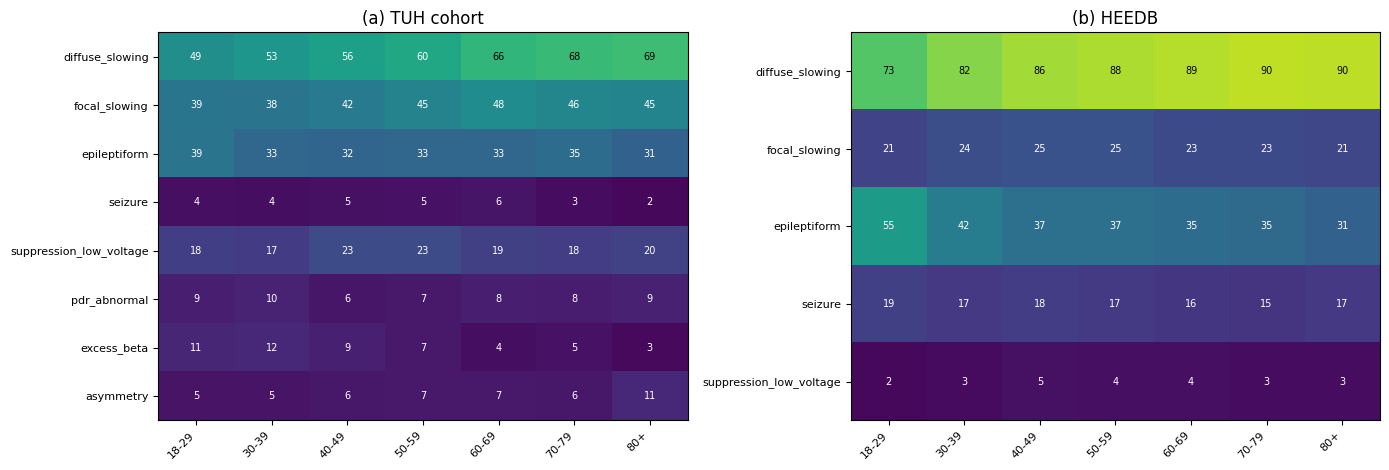

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, c in zip(axes, ["TUH cohort", "HEEDB"]):
    t = ca.abnormal_types(df[df.corpus == c], by="age_group").droplevel(0).drop(columns="n")
    t = t.loc[:, t.notna().any()].T
    heat(ax, t, c, vmax=100)
finish(fig, axes)

### Tables 4.2–4.3. Which abnormality types go with which pathology

The lift of type $t$ among abnormal recordings with pathology $p$ over all abnormal recordings of the corpus:

$$
L_{pt} = \frac{s_t(A \cap \{i : x_{ip} = 1\})}{s_t(A)}
\tag{4.2}
$$

with $s_t$ of Eq. (4.1) (`clinical_analytics.type_by_pathology_lift`). $L > 1$: the type is over-represented
in that pathology (e.g. epileptiform discharges in epilepsy). Pathologies with at least 10 such recordings;
HEEDB cells under 10 positives are blank.

### Table 4.2. TUH cohort: lift of abnormality types by pathology

In [20]:
display(numbered_table(ca.type_by_pathology_lift(df, "TUH cohort"), "4.2", "TUH cohort lift (Eq. 4.2)", precision=2))

,diffuse_slowing,focal_slowing,epileptiform,seizure,suppression_low_voltage,pdr_abnormal,excess_beta,asymmetry
seizure_epilepsy,0.98,1.05,1.27,4.35,0.72,0.94,0.77,0.33
stroke_cerebrovascular,1.13,1.26,1.07,2.10,1.35,0.49,0.54,0.61
dementia,1.40,1.06,1.19,0.75,0.58,1.05,1.23,–
multiple_sclerosis,1.07,1.07,1.05,–,1.45,0.74,1.74,1.74
tbi,1.01,1.32,0.89,1.63,1.07,1.06,0.83,0.12
depression,0.78,0.64,0.52,3.96,0.35,0.44,2.86,–
anxiety,0.59,1.15,0.76,–,0.17,2.14,2.76,–
bipolar,1.08,0.72,1.00,1.33,1.03,1.01,2.77,0.71
schizophrenia,1.19,0.92,0.63,–,1.79,0.54,–,0.63
substance_use,1.07,0.66,0.79,0.58,1.01,1.16,1.93,0.57


### Table 4.3. HEEDB: lift of abnormality types by pathology

In [21]:
lh = ca.type_by_pathology_lift(df, "HEEDB")
display(numbered_table(lh.loc[:, lh.notna().any()], "4.3", "HEEDB lift (Eq. 4.2)", precision=2))

,diffuse_slowing,focal_slowing,epileptiform,seizure,suppression_low_voltage
seizure_epilepsy,0.98,1.25,1.28,1.05,0.83
stroke_cerebrovascular,1.04,1.16,0.86,0.78,0.96
dementia,1.04,0.91,0.78,0.77,0.63
parkinson_movement,1.02,0.90,0.90,0.84,1.06
multiple_sclerosis,1.00,0.80,0.96,0.73,0.95
depression,1.02,0.95,0.92,0.82,0.97
adhd,0.95,0.94,1.05,0.90,0.70
headache_migraine,1.02,1.27,0.99,0.85,0.75
sleep_disorder,1.02,0.96,0.91,0.76,0.91
brain_tumor,1.04,1.69,1.03,0.89,0.27


## 5. Findings

**Demographics and verdict (Tables 2.1–2.4, Figures 2.1–2.2).**

* **Age and sex mix.** The three corpora are adult and close in age (mean 49 years for TUAB, 52 for the TUH
  cohort, 54 for HEEDB) and about half women (51–53 %).
* **Report coverage.** TUAB is balanced by design (51 % normal). The TUH cohort is 53 % abnormal. Half of the
  HEEDB recordings have no report verdict (49 % unknown); among the rest, 60 % are abnormal.
* **Abnormal share rises with age** in every corpus (Eq. (2.1), Figure 2.2): from 30–44 % under 40 to 72–77 % at
  80+. At every age men are slightly more often abnormal than women (TUAB 52 vs 47 %, TUH cohort 61 vs 55 %,
  HEEDB 61 vs 60 %).
* **Consequence for training.** Age and abnormality are strongly confounded. A brain-age model trained on all
  recordings sees mostly abnormal EEGs at old age, and a pathology model can lean on age-related EEG change
  (cf. the bias-corrected brain-age gap in `docs/brain_age_bias_correction.md`).

**Pathologies (Tables 3.1–3.5, Figures 3.1–3.3).**

* **The corpora describe pathology very differently.**
  * HEEDB's per-patient ICD-10 history is rich: seizure disorders 35 %, headache 28 %, sleep disorders 22 %,
    depression 20 %, stroke / cerebrovascular 15 %, movement disorders 15 %, dementia 8 %, tumours 6 %.
  * The TUH sheet notes much less per session: seizure / epilepsy 9 %, stroke 4 %, substance use 4 %, and keyword
    mentions such as altered mental status 8 % or syncope 4 %.
  * TUAB's diagnosis columns are essentially empty (Section 1).
  * Rates are therefore comparable *within* a corpus, not across corpora.
* **Headache / migraine** is the most common non-seizure category in HEEDB (28 %).
  * **Sex:** about 1.4× more frequent in women (32 vs 23 %); the TUH mentions show the same sex ratio (TUAB 7.4
    vs 2.9 %, TUH cohort 3.0 vs 1.3 %).
  * **Age:** in TUH it is a disease of the young (3–4 % of mentions under 50, < 1 % above 60); HEEDB's lifetime
    codes stay at 23–32 % across ages (Figure 3.3).
  * **In TUH it marks a normal EEG:** 10 % of TUAB and 33 % of TUH-cohort recordings with a headache mention are
    abnormal, against 46 % and 58 % without (Table 3.3).
  * **In HEEDB it has no such effect** (60 % vs 60 %), because the ICD code is lifetime history and co-occurs
    with other neurological disease: of HEEDB headache patients' recordings, 52 % also carry a seizure disorder,
    38 % depression and 39 % a sleep disorder (Table 3.4).
* **Pathologies that raise the abnormal share most** (Eq. (3.2), Table 3.3):
  * stroke (TUH cohort 82 % vs 56 % abnormal, +26 pp);
  * anoxic injury (+24 pp) and altered mental status (+23 pp);
  * brain tumour (+14 pp TUH, +19 pp HEEDB) and CNS infection (+18 pp HEEDB);
  * dementia (+15 pp TUH, +15 pp HEEDB).
* **Pathologies that do not raise it.** Psychiatric and benign neurological categories go with an equal or
  *lower* abnormal share:
  * TUH cohort: depression −13 pp, anxiety −9, ADHD −14, MS −6, headache −25, syncope −24.
  * HEEDB: depression −1, MS −3, headache 0, ADHD −16.
  * Their patients are younger and their diagnoses leave no consistent EEG trace, so they are hard targets for
    an EEG classifier.
* **Sex differences beyond headache:**
  * substance use is twice as frequent in men in TUH (5.6 vs 2.9 %, TUAB 6.0 vs 2.5 %);
  * in HEEDB, depression (23 vs 17 %) and multiple sclerosis (1.9 vs 0.9 %) are more frequent in women;
  * stroke is slightly more frequent in men in both corpora (4.2 vs 3.7 %, 15.5 vs 13.7 %).
* **Comorbidity is the rule in HEEDB:** 43 % of the dementia patients' recordings also carry a seizure
  disorder, and 33 % stroke (Table 3.4). Per-pathology targets are therefore far from mutually exclusive, and a
  multi-label (not multi-class) formulation is the right one for the pathology heads.

**Abnormality types (Tables 4.1–4.3, Figure 4.1).**

* **Slowing dominates.**
  * TUH: diffuse slowing in 61 % and focal slowing in 44 % of abnormal reasons, epileptiform discharges in 34 %,
    suppression / low voltage in 20 %, seizures in 4 %.
  * HEEDB's structured findings name generalised slowing in 87 %, epileptiform or periodic discharges in 38 %,
    focal slowing in 23 % and a seizure in 17 % of abnormal recordings.
  * The higher HEEDB generalised-slowing and seizure rates partly reflect structured coding (every mention
    counts) against keyword rules on a short TUH reason text.
* **Types follow the pathologies as expected** (lift, Eq. (4.2)):
  * TUH: seizures are 4.4× over-represented and epileptiform discharges 1.3× in seizure / epilepsy patients;
    suppression / low voltage is 2.5× over-represented after anoxic injury; focal slowing 1.7× with brain
    tumours and 1.3× after stroke.
  * HEEDB shows the same focal-slowing lift for tumours (1.7×) and the epileptiform lift for seizure disorders
    (1.3×).
* **Rare TUH groups, wide error bars.** In the TUH cohort the rarer categories (MS, ADHD, schizophrenia,
  dementia) have under 100 positives each. Their prevalence and lifts carry wide uncertainty and should not be
  over-read.

**What this means for the pathology model (E2P).** E2P (TUH + HEEDB, status + 17 diagnosis groups,
`dataset_maker/make_multitask_targets.py`) inherits these properties:

* **HEEDB dominates most groups.** It provides most positives for seizure, stroke, dementia, depression and all
  of headache, sleep, tumour and movement disorders.
* **TUH-only groups.** The psychiatric, substance and TBI groups come from TUH only (HEEDB unknown).
* **Undated labels.** HEEDB groups are lifetime diagnoses, so EEG-invisible history (e.g. a remote headache
  code) caps the reachable ROC-AUC.
* **Expected detectability** (Table 3.3): stroke, tumour, CNS infection, dementia and the seizure groups should
  be detectable above chance; depression, ADHD, MS and headache will be close to it.

## 6. The classes predicted by E2P, the pathology model

E2P (`/data/runs/heedb/submit_e2p_1gpu.sh`, docs/heedb_onboarding_plan.md) trains on the joint TUH + HEEDB cohort
`tuh_heedb_v1`, on E2 / E2L's split, a **multi-label** classifier without an age prediction: 18 independent
sigmoid outputs. Its targets are `multitask_targets_v2.npz` (`dataset_maker/make_multitask_targets.py`):

* `status_abnormal`: the EEG report's verdict (1 = abnormal);
* 13 NEDC diagnosis groups: `clinical_seizure`, `electrographic_seizure`, `epilepsy`, `stroke`, `tbi`,
  `substance`, `bipolar`, `anxiety`, `depression`, `schizophrenia`, `dementia` (incl. Alzheimer's), `ms` and
  `other` (Parkinson's, ADHD). TUH from the NEDC sheet; HEEDB from the ICD-10 based `dx_*` flags;
* 4 HEEDB ICD-10 groups: `headache_disorders` (incl. migraine), `sleep_disorders`,
  `intracranial_and_spinal_tumors`, `movement_and_cerebellar_disorders` (unknown for TUH).

A label is unknown, and left out of the loss and the metrics, when the recording has no report verdict (status),
when its session is not in the NEDC sheet (TUH), when the patient has no ICD-10 record (HEEDB), or when the
dataset does not code the group at all (blank rows below).

### Table 6.1. Targets: known labels, positives and prevalence per dataset

All splits together. `known` = recordings whose label is known, `positive` = positives, `%` = prevalence,
Eq. (3.1).

In [22]:
mt = ca.multitask_target_stats()
order = list(dict.fromkeys(mt.target))
tot = mt.groupby(["target", "dataset"], sort=False)[["known", "positive"]].sum(min_count=1).unstack("dataset")
tot = tot.reindex(order)
for d in ("TUH", "HEEDB"):
    tot[("%", d)] = 100 * tot[("positive", d)] / tot[("known", d)].replace(0, np.nan)
tot = tot.reindex(columns=pd.MultiIndex.from_product([["known", "positive", "%"], ["TUH", "HEEDB"]]))
display(numbered_table(tot, "6.1", "E2P targets per dataset", precision=1))

### Table 6.2. Positives per split and dataset

Positive recordings of each target in the train / validation / test splits (E2's split). TUH test is TUAB eval:
the NEDC sheet hardly annotates diagnoses for TUAB sessions (Section 1), so the TUH test split has almost no
pathology positives, and TUH pathology can only be judged on validation. HEEDB counts under 10 are blank.

In [23]:
pos = mt.pivot_table(index="target", columns=["split", "dataset"], values="positive", aggfunc="first", sort=False)
pos = pos.reindex(order).reindex(columns=pd.MultiIndex.from_product([["train", "val", "test"], ["TUH", "HEEDB"]]))
display(numbered_table(pos, "6.2", "Positives per split and dataset", precision=0))

### Table 6.3. Prevalence per split and dataset (%)

Eq. (3.1) per split and dataset, among the recordings whose label is known.

In [24]:
prv = mt.pivot_table(index="target", columns=["split", "dataset"], values="prevalence %", aggfunc="first", sort=False)
prv = prv.reindex(order).reindex(columns=pd.MultiIndex.from_product([["train", "val", "test"], ["TUH", "HEEDB"]]))
display(numbered_table(prv, "6.3", "Prevalence per split and dataset (%)", precision=1))